# Planning and Learning: Dyna

This notebook implements the Dyna approach to combine learning and planning. 

## Installation and Setup

In [4]:
# uncomment if needed
# %pip install "gym-classics2 @ git+https://github.com/mhahsler/gym-classics2.git"

In [5]:
import numpy as np
np.set_printoptions(precision=2)

SEED = 42
rng = np.random.default_rng(SEED)

In [6]:
import gymnasium as gym
import gym_classics2
gym_classics2.register('gymnasium')

from gym_classics2.animation import gridworld_animate                               
from gym_classics2.algorithms.policy import random_policy

/home/mhahsler/miniconda3/envs/reinforcement-learning/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The Dyna Maze

Example from Sutton/Barto Chapter 8.

In [7]:
gym_env = gym.make('DynaMaze-v0', tabular = True)
env = gym_env.unwrapped
env.reset(seed=SEED)

(3, {})

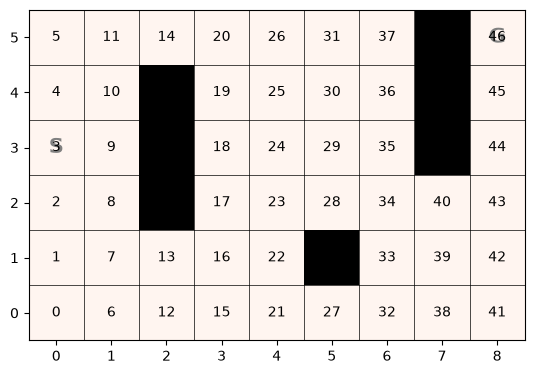

In [8]:
env.image()

## Optimal Policy

This environment has model access, so we can for comparison use value iteration to find the optimal policy.

Note: This maze uses a discount factor of 0.95 to find the shortest path. Otherwise, the value function would be 1 for every state.

Value Iteration: 0it [00:00, ?it/s]

Value Iteration: 14it [00:00, 285.83it/s]


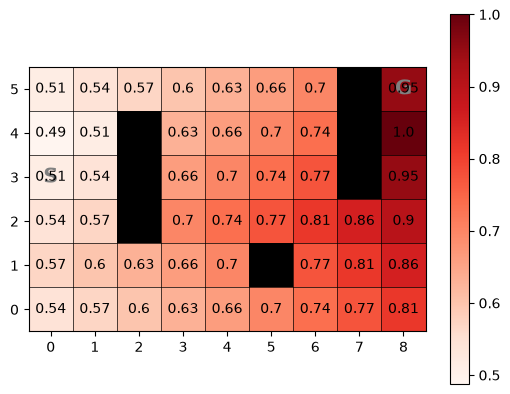

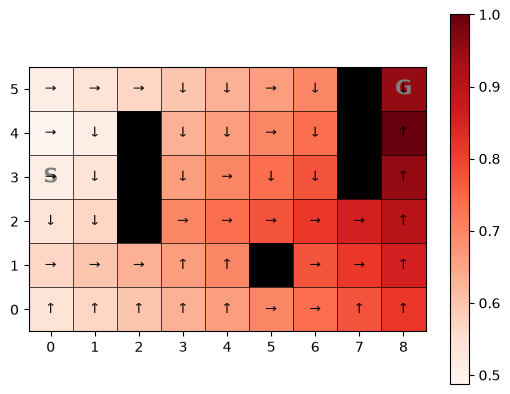

In [11]:
from gym_classics2.algorithms.dynamic_programming import value_iteration
from gym_classics2.algorithms.policy import greedy_policy

V_star = value_iteration(env, discount=.95)
policy_star = greedy_policy(V_star, env, discount=.95, rng=rng)

env.image(V_star, labels=True)
env.image(V_star, policy=policy_star)

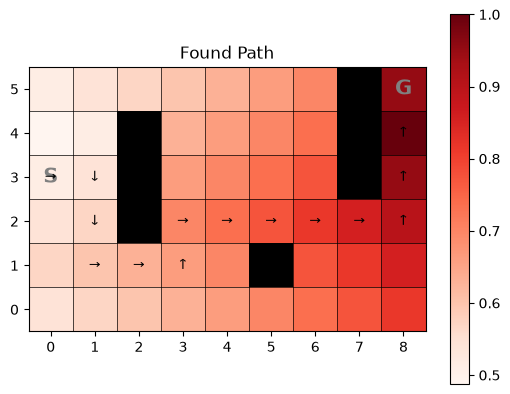

In [12]:
from gym_classics2.algorithms.monte_carlo_methods import sample_episode

path = sample_episode(env, policy=policy_star, max_len=100)
env.image(V=V_star, policy=policy_star, episode=path, title='Found Path')

## Dyna
![Algorithm: Dyna](https://raw.githubusercontent.com/mhahsler/Introduction_to_Reinforcement_Learning/refs/heads/main/figures/RL-Intro_Alg_Dyna.png)

In [29]:
from tqdm import tqdm

# np.argmax does not break ties randomly
def random_argmax(x, rng):
    return rng.choice(np.where(x == np.max(x))[0])

def Dyna(env, discount, alpha, epsilon, n=100, n_planning=5, verbose=False, rng=None):
    rng = np.random.default_rng(rng)
    Q = np.zeros((len(env.states()), len(env.actions())))
    model = {}
    
    for i in tqdm(range(n), desc="Dyna", disable=verbose):
        
        # Learning: Q-Learning using the Environment
        s, r = env.reset()
          
        done = False
        while not done:
            # epsilon-greedy choice w.r.t. Q 
            if rng.random() > epsilon:
                a = random_argmax(Q[s,:], rng)
            else:
                a = rng.integers(env.action_space.n)
            
            sp, r, done, _, _ = env.step(a)
        
            # update deterministic model of the environment
            model[(s, a)] = (sp, r)
        
            Q[s,a] = Q[s,a] + alpha * (r + discount * np.max(Q[sp,:]) - Q[s,a])
            
            s = sp
        
            # Planning: Q-Learning using the Model
            for _ in range(n_planning):
                # sample a previously observed state-action pair
                (s2, a2) = rng.choice(list(model.keys()))
                sp2, r2 = model[(s2, a2)]     
                Q[s2,a2] = Q[s2,a2] + alpha * (r2 + discount * np.max(Q[sp2,:]) - Q[s2,a2])
 
            
    return Q

### No Planning

In [49]:
Q = Dyna(env, discount=.95, alpha=.1, epsilon=.1, n=3, n_planning=0, rng=rng)

Dyna: 100%|██████████| 3/3 [00:00<00:00, 15.68it/s]


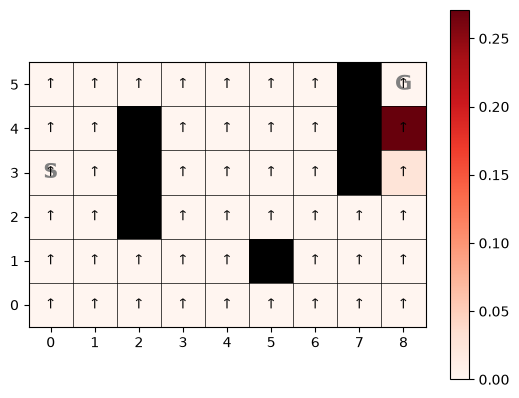

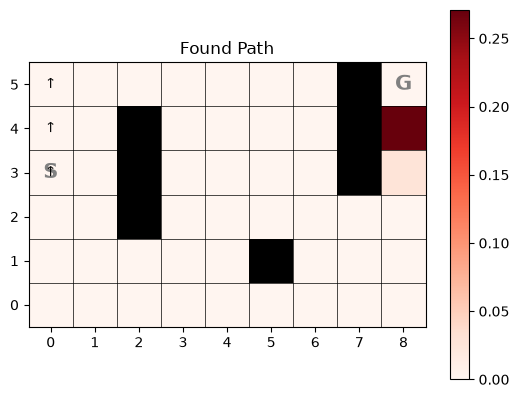

In [50]:
policy = np.argmax(Q, axis=1)
V = np.max(Q, axis = 1)

env.image(V, policy = policy)
path = sample_episode(env, policy=policy, max_len=100)
env.image(V=V, policy=policy, episode=path, title='Found Path')

### With Planning Steps

In [47]:
Q = Dyna(env, discount=.95, alpha=.1, epsilon=.1, n=3, n_planning=50, rng=rng)

Dyna: 100%|██████████| 3/3 [00:01<00:00,  2.18it/s]


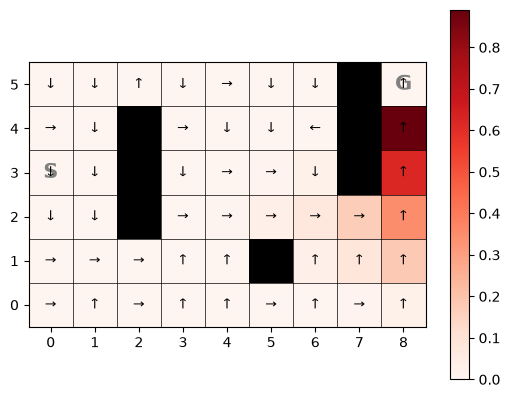

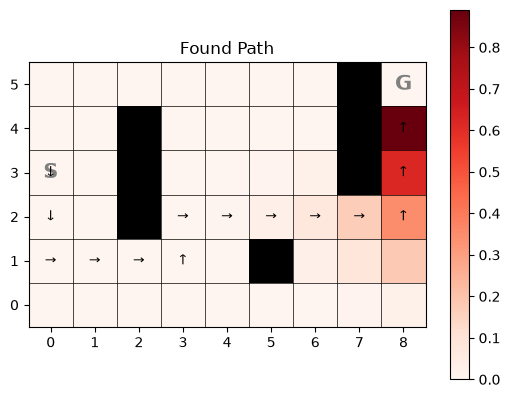

In [48]:
policy = np.argmax(Q, axis=1)
V = np.max(Q, axis = 1)

env.image(V, policy = policy)
path = sample_episode(env, policy=policy, max_len=100)
env.image(V=V, policy=policy, episode=path, title='Found Path')


&copy; 2025 [Michael Hahsler](https://michael.hahsler.net). 
This work is openly licensed under [Creative Commons Attribution-ShareAlike 4.0 International (CC BY-SA 4.0) License](https://creativecommons.org/licenses/by-sa/4.0/)

![CC BY-SA 4.0](https://licensebuttons.net/l/by-sa/3.0/88x31.png)